# Chapter 10 — Reinforcement learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mengrenman/artificial_intelligence_engines/blob/main/notebooks/10_reinforcement.ipynb)

Tabular temporal-difference (TD) methods from Stone (2020), Chapter 10, implemented in `scripts/reinforcement.py`:

1. **Prediction**: TD(0) and TD($\lambda$) on the 5-state random walk.
2. **Control**: SARSA vs Q-learning on the cliff-walking gridworld.
3. **Balancing a pole** (Section 10.10) with the book's reward function.

In [1]:
# Colab setup: install the companion package (does nothing when run locally).
try:
    import google.colab  # noqa: F401
    %pip install -q git+https://github.com/mengrenman/artificial_intelligence_engines
except ImportError:
    pass

In [2]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
from scripts.reinforcement import (
    RW_TRUE_VALUES, random_walk_episodes, td0, td_lambda,
    CliffWalk, sarsa, q_learning, greedy_path,
    CartPole, Discretiser, balance_pole, pole_reward, run_greedy_pole,
)

## 1. TD prediction on a random walk

States A–E sit between two terminal states; every episode starts at C and steps left or right with probability ½. Exiting right gives reward 1, so with $\gamma=1$ the true values are $v_\pi = 1/6, 2/6, \dots, 5/6$.

**TD(0)** (Eqs 10.27–10.28):
$$\delta_t = R_{t+1} + \gamma V(s_{t+1}) - V(s_t), \qquad V(s_t) \leftarrow V(s_t) + \epsilon\,\delta_t .$$

**TD($\lambda$)** keeps an eligibility trace per state (Eqs 10.30–10.31): $e \leftarrow \gamma\lambda e$, then $e(s_t) \leftarrow e(s_t)+1$, and updates *all* states, $V(s) \leftarrow V(s) + \epsilon\,\delta_t\, e(s)$. (Eq 10.32 in the book is written for $V(s_t)$ only; we use the standard form, which is identical for $\lambda=0$.)

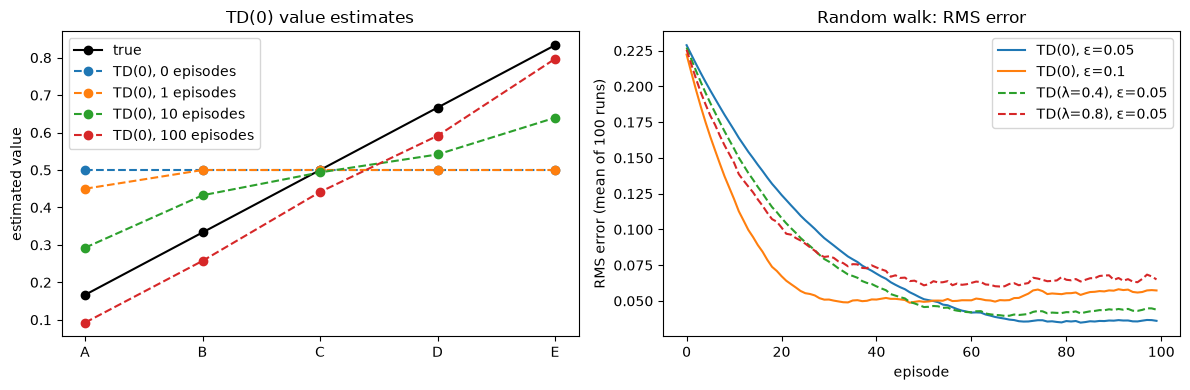

In [3]:
episodes = random_walk_episodes(100, seed=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(range(1, 6), RW_TRUE_VALUES, 'k-o', label='true')
for n in [0, 1, 10, 100]:
    V, _ = td0(episodes[:n], lr=0.1)
    ax.plot(range(1, 6), V[1:-1], 'o--', label=f'TD(0), {n} episodes')
ax.set_xticks(range(1, 6)); ax.set_xticklabels(list('ABCDE'))
ax.set_ylabel('estimated value'); ax.legend(); ax.set_title('TD(0) value estimates')

n_runs, n_ep = 100, 100
ax = axes[1]
for lr in [0.05, 0.1]:
    err = np.mean([td0(random_walk_episodes(n_ep, seed=r), lr=lr, true_values=RW_TRUE_VALUES)[1]
                   for r in range(n_runs)], axis=0)
    ax.plot(err, label=f'TD(0), ε={lr}')
for lam in [0.4, 0.8]:
    err = np.mean([td_lambda(random_walk_episodes(n_ep, seed=r), lam, lr=0.05,
                             true_values=RW_TRUE_VALUES)[1] for r in range(n_runs)], axis=0)
    ax.plot(err, '--', label=f'TD(λ={lam}), ε=0.05')
ax.set_xlabel('episode'); ax.set_ylabel(f'RMS error (mean of {n_runs} runs)')
ax.legend(); ax.set_title('Random walk: RMS error'); plt.tight_layout()

Eligibility traces propagate the reward back to earlier states within a single episode, so TD($\lambda$) reduces the error faster early on; with constant $\epsilon$ all methods plateau at a noise floor set by the learning rate.

## 2. SARSA vs Q-learning on the cliff

A 4×12 grid: start bottom-left (S), goal bottom-right (G), and a cliff between them (reward −100 and back to start); every other step costs −1. Both agents use an $\varepsilon$-greedy policy with $\varepsilon=0.1$, learning rate $\epsilon=0.5$, $\gamma=1$.

* **SARSA** (on-policy, Eq 10.41): $Q(s_t,a_t) \leftarrow Q(s_t,a_t) + \epsilon[R_{t+1} + \gamma Q(s_{t+1},a_{t+1}) - Q(s_t,a_t)]$
* **Q-learning** (off-policy, Eq 10.42): $Q(s_t,a_t) \leftarrow Q(s_t,a_t) + \epsilon[R_{t+1} + \gamma \max_a Q(s_{t+1},a) - Q(s_t,a_t)]$

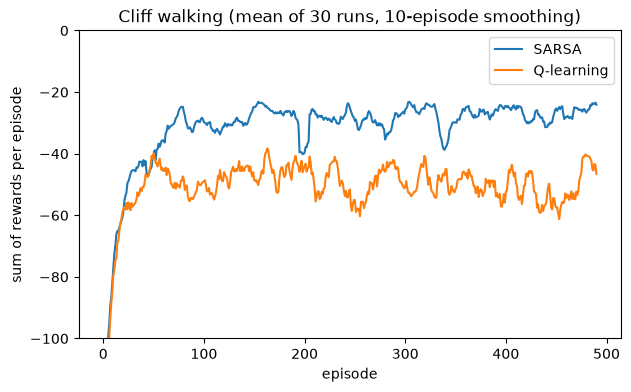

In [4]:
env = CliffWalk()
n_runs, n_ep = 30, 500
R_s = np.mean([sarsa(env, n_ep, seed=r)[1] for r in range(n_runs)], axis=0)
R_q = np.mean([q_learning(env, n_ep, seed=r)[1] for r in range(n_runs)], axis=0)
smooth = lambda y, k=10: np.convolve(y, np.ones(k) / k, mode='valid')
plt.figure(figsize=(7, 4))
plt.plot(smooth(R_s), label='SARSA'); plt.plot(smooth(R_q), label='Q-learning')
plt.ylim(-100, 0); plt.xlabel('episode'); plt.ylabel('sum of rewards per episode')
plt.title(f'Cliff walking (mean of {n_runs} runs, 10-episode smoothing)'); plt.legend();

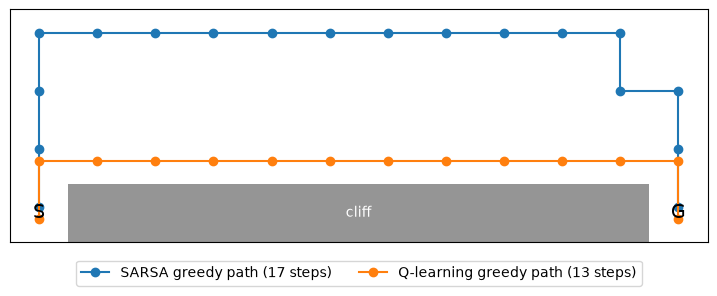

In [5]:
Q_s, _ = sarsa(env, n_ep, seed=0)
Q_q, _ = q_learning(env, n_ep, seed=0)
fig, ax = plt.subplots(figsize=(9, 3.5))
grid = np.zeros((env.n_rows, env.n_cols)); grid[-1, 1:-1] = 1
ax.imshow(grid, cmap='Greys', vmin=0, vmax=2)
for Q, name, col, off in [(Q_s, 'SARSA', 'tab:blue', -0.1), (Q_q, 'Q-learning', 'tab:orange', 0.1)]:
    p = np.array(greedy_path(env, Q))
    ax.plot(p[:, 1], p[:, 0] + off, '-o', color=col, label=f'{name} greedy path ({len(p) - 1} steps)')
ax.text(0, 3, 'S', ha='center', va='center', fontsize=14); ax.text(11, 3, 'G', ha='center', va='center', fontsize=14)
ax.text(5.5, 3, 'cliff', ha='center', va='center', color='w')
ax.set_xticks([]); ax.set_yticks([]); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=2);

Q-learning learns the values of the *optimal* (greedy) policy, so its greedy path is the 13-step route along the cliff edge — but while it explores it occasionally falls off, so its online reward is lower. SARSA learns the value of the policy it actually follows (including exploratory moves) and therefore prefers the longer, safe route away from the edge.

## 3. Balancing a pole (Section 10.10)

State $s=(x,\dot x,\theta,\dot\theta)$, three actions (push left, nothing, push right). Following the book's box (page 165):

* episode ends if $|x|>4$, $|\theta|>45^\circ$, or after 1000 actions;
* while balancing $R_{t+1} = 10 - 1000\theta^2 - 5|x| - 10|\dot x|$; on failure $R_{t+1} = -10000 - 50|x| - 100|\theta|$;
* learning rate $\epsilon = 0.3$; exploration probability $\varepsilon = 0.001$, multiplied by 0.99 each episode.

Choices not in the book: classic cart–pole physics (Barto, Sutton & Anderson 1983; $F=\pm10$ N, $\Delta t = 0.02$ s, Euler integration), $\theta$ in radians, $\gamma=0.99$, a BOXES-style discretisation of the state ($3\times3\times8\times6$ boxes), and a small random initial pole angle. The box's exploration test "if $\varepsilon <$ random number then random action" is a typo for the usual $\varepsilon$-greedy rule.

In [6]:
cart = CartPole()
s, traj = (0.0, 0.0, 0.02, 0.0), []
while not cart.failed(s):
    s = cart.step(s, 1); traj.append(s)
traj = np.array(traj)
print(f'Without control the pole falls after {len(traj)} steps ({len(traj) * cart.dt:.2f} s)')
print('reward upright at centre:', pole_reward((0, 0, 0, 0), True),
      '| reward on failure:', pole_reward(traj[-1], False))

Without control the pole falls after 58 steps (1.16 s)
reward upright at centre: 10.0 | reward on failure: -10084.077311426636


trained 2 × 3 agents × 500 episodes in 14.2 s


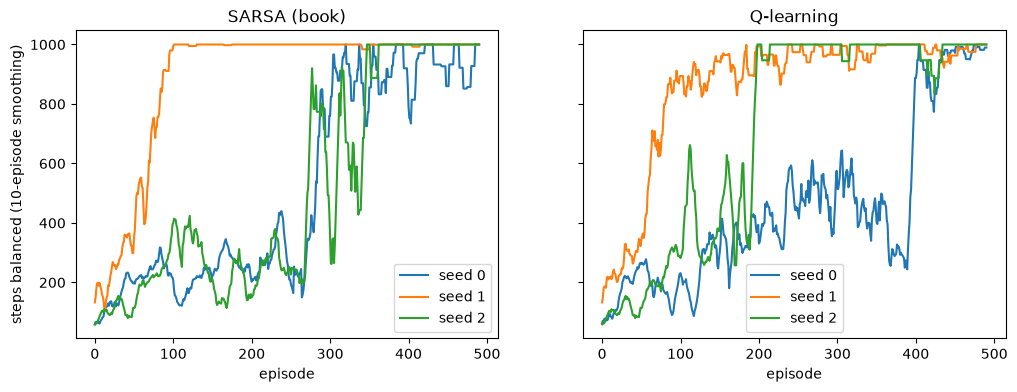

In [7]:
t0 = time.time()
results = {m: [balance_pole(500, method=m, seed=r) for r in range(3)] for m in ['sarsa', 'q']}
print(f'trained 2 × 3 agents × 500 episodes in {time.time() - t0:.1f} s')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (m, runs) in zip(axes, results.items()):
    for r, res in enumerate(runs):
        ax.plot(smooth(res.steps, 10), label=f'seed {r}')
    ax.set_title({'sarsa': 'SARSA (book)', 'q': 'Q-learning'}[m])
    ax.set_xlabel('episode'); ax.legend()
axes[0].set_ylabel('steps balanced (10-episode smoothing)');

As in the book, SARSA learns to balance the pole for the maximum 1000 actions within about 500 episodes. Below: the learned state-value function $V(\theta,\dot\theta)$, obtained (like Fig 10.6b) by taking $\max_a Q$ and averaging over the cart position and velocity boxes, and a greedy roll-out of the learned policy.

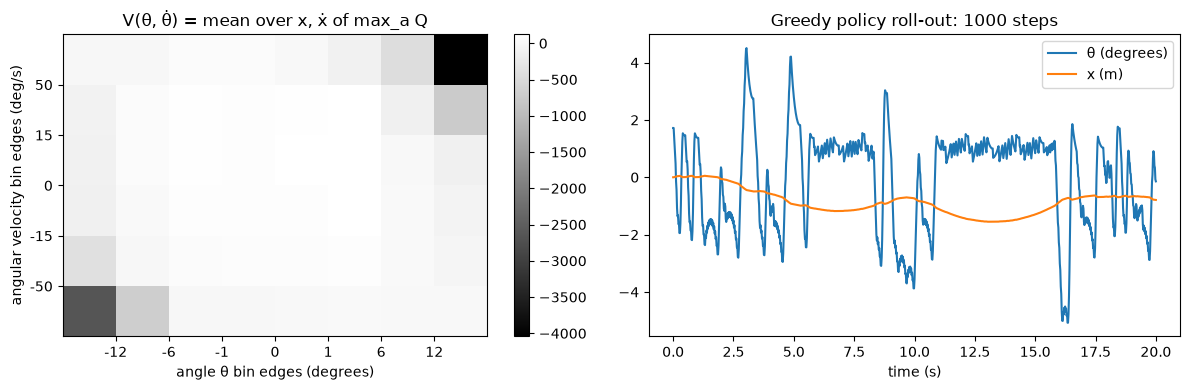

In [8]:
disc = Discretiser()
res = results['sarsa'][1]
V = res.Q.max(axis=1).reshape(disc.shape).mean(axis=(0, 1))
th_e, thd_e = np.degrees(disc.edges[2]), np.degrees(disc.edges[3])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im = axes[0].imshow(V.T, origin='lower', cmap='gray', aspect='auto')
axes[0].set_xticks(np.arange(len(th_e) + 1) - 0.5, minor=False)
axes[0].set_xticks(np.arange(len(th_e)) + 0.5); axes[0].set_xticklabels([f'{v:.0f}' for v in th_e])
axes[0].set_yticks(np.arange(len(thd_e)) + 0.5); axes[0].set_yticklabels([f'{v:.0f}' for v in thd_e])
axes[0].set_xlabel('angle θ bin edges (degrees)'); axes[0].set_ylabel('angular velocity bin edges (deg/s)')
axes[0].set_title('V(θ, θ̇) = mean over x, ẋ of max_a Q'); plt.colorbar(im, ax=axes[0])
traj = run_greedy_pole(res.Q, s0=(0.0, 0.0, 0.03, 0.0))
t = np.arange(len(traj)) * CartPole().dt
axes[1].plot(t, np.degrees(traj[:, 2]), label='θ (degrees)')
axes[1].plot(t, traj[:, 0], label='x (m)')
axes[1].set_xlabel('time (s)'); axes[1].legend()
axes[1].set_title(f'Greedy policy roll-out: {len(traj) - 1} steps'); plt.tight_layout()

Low (dark) values correspond to large angles, particularly when the angular velocity carries the pole further from vertical — the same qualitative picture as Fig 10.6b. (Unvisited boxes keep their initial value 0.)